# Dumpsite Detection — End-to-End Workflow (DPWMS / GEDH Module 1)

Guinea Environmental Digital Hub, Digital Plastic Waste Management System.

This notebook is the **executable record of the dumpsite detection workflow**:
how the scan footprint is defined, how labels were collected, which design
questions were tested and what they returned, and what the model actually does.
Every step calls a tracked script in `plasticwaste_tool/`, so any stage can be
re-run independently and nothing here depends on a chat transcript.

**Status.** Two products ship, both on free Esri imagery:

1. **On-demand location checker** — a user drops a pin and the model scores the 80 m window around it,
   the point-centred condition where it performs best (ROC-AUC 0.832 on Esri, 0.911 on licensed
   Google). Part 2.5.
2. **National screening scan** — the two-stage cascade over Guinea's settled footprint, both stages on
   free Esri imagery, published to **analysts only** as a review queue, never as a public map. On two
   hand-labelled blind grids, at the recommended medium tier (≥ 0.70), its precision is 0.35 (Conakry)
   and 0.59 (Boké) — about 1.3× the base rate — and it finds 46% and 23% of sites. Part 3.

What limits both: the model separates disturbed ground from natural cover, but not waste from other
disturbed ground — its score does not rise with the amount of waste, and construction sites score
highest (Part 2.2). The binding constraint is the volume of task-specific labels, not the architecture
(Part 2.3).

---

## The pipeline

```
09_national_footprint.py budget    define the scan footprint (GHSL SMOD mask)
09_national_footprint.py sample    draw an unbiased random labelling sample
manual_qa/regions/label_tool.py    human labelling (click-through GUI)
08_point_model.py build-samples    expand positives to one row per dump pin
08_point_model.py fetch            pull imagery (Esri free | Google licensed)
08_point_model.py evaluate         nested CV, spatial blocks, honest metrics
08_point_model.py sheets           contact sheets: what it flags, what it misses
08_point_model.py archive          snapshot a run so results stay citable
```

Supporting modules: `05_guinea_inference.py` (tile fetchers, placeholder
detection), `02c_feature_probe.py` (feature extraction, spatial blocking),
`02d_benchmark_features.py` (representations, paired bootstrap).

## Three results that shaped the design

1. **Resolution does not matter; footprint does.** These were repeatedly
   conflated. Degrading imagery 0.29 → 1.18 m/px changed nothing
   (ΔAUC −0.011, P=0.70). Changing the crop from a 250 m cell to an 80 m
   window centred on the dump changed everything.
2. **At 250 m the model was a settlement detector, not a waste detector.**
   Residential negatives outscored real dumpsites (0.626 vs 0.618). It reached
   52% precision only because dumps sit in settlements.
3. **Google z19 beats free Esri z17 at 80 m, significantly** (ΔAP +0.144,
   P = 0.004). The platform cannot license Google imagery for this use, so the
   deployed stage 2 runs on Esri with a head fitted on Esri (Part 3).

In [1]:
# torch MUST initialise before the GDAL/GEE stack on Windows: both ship
# native DLLs and whichever loads first wins. Without this, importing
# torch after geopandas fails with WinError 1114.
import torch  # noqa: F401

import json, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd

ROOT = Path.cwd()
TOOL = ROOT / "plasticwaste_tool"
MQ   = TOOL / "manual_qa"
REG  = MQ / "regions"
RUNS = MQ / "runs"
assert TOOL.exists(), f"run this notebook from {ROOT.parent if not TOOL.exists() else ROOT}"

def run(args, timeout=7200):
    '''Call a pipeline script and stream its output.'''
    cmd = [sys.executable] + args
    print("$", " ".join(str(c) for c in cmd), flush=True)
    p = subprocess.run(cmd, cwd=TOOL, capture_output=True, text=True, timeout=timeout)
    print(p.stdout[-6000:])
    if p.returncode != 0:
        print("STDERR:", p.stderr[-3000:])
    return p

def metrics(source, tile_m=80):
    f = MQ / f"_metrics_pt{tile_m}_{source}.json"
    return json.loads(f.read_text(encoding="utf-8")) if f.exists() else None

print("tool dir :", TOOL)
print("runs     :", [p.name for p in sorted(RUNS.glob('*'))] if RUNS.exists() else "none")

tool dir : c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\plasticwaste_tool
runs     : ['blindgrid_boke', 'blindgrid_esri', 'cascade_demo_conakry', 'esri_80m_20260915', 'google_80m_20260915', 'leakage', 'marida', 'river_fdi']


---
## 1. Scan footprint — what "nation-wide" means

Guinea is 244,006 km², i.e. **3,904,090 cells at 250 m**. Every cell needs an
HTTP image fetch plus a CNN forward pass, and *fetching*, not compute, is the
binding cost — an exhaustive scan is ~5.6 days of continuous requests.

Informal dumping sits at the settlement fringe, so the scan is masked to
**GHSL Degree of Urbanisation (SMOD) ≥ 21** — urban centre, dense cluster,
semi-dense, suburban — plus a **1 km fringe**. SMOD is the EU/UN standard
settlement classification used for SDG indicator reporting, so coverage is
defined by a published layer rather than a hand-picked list of towns.

Two non-obvious findings from measuring it:

* *"All settled land"* (SMOD ≥ 11) is useless — very-low-density rural covers
  99.5% of Guinea, indistinguishable from scanning everything.
* A **500 m fringe is indistinguishable from no fringe**, because SMOD's 1 km
  pixels cannot resolve it. The real choices are 0, 1 km and 2 km.

1 km is chosen: the literature puts illegal dumping overwhelmingly within
250–500 m of populated land, with ~1 km capturing essentially all validated
sites; 2 km costs 64% more for little gain.

> Requires Earth Engine credentials and takes a few minutes. The measured
> result is tabulated below the cell so the notebook reads without running it.

In [2]:
# run(["09_national_footprint.py", "budget"])   # uncomment to recompute (GEE, ~5 min)

pd.DataFrame([
    ("whole country",              244006, 3904090, "100.00%", "5.6 d", "18.1 d"),
    ("SMOD>=21 (urban+suburban)",    2584,   41351,   "1.06%", "1.4 h",  "4.6 h"),
    ("  + 1 km fringe  <- CHOSEN",   5583,   89336,   "2.29%", "3.1 h",  "9.9 h"),
    ("  + 2 km fringe",              9152,  146433,   "3.75%", "5.1 h", "16.3 h"),
    ("all settled (SMOD>=11)",     242871, 3885932,  "99.53%", "5.6 d", "18.0 d"),
], columns=["scan footprint", "km2", "250m cells", "% country",
            "fetch @8/s", "CPU @2.5/s"])

,scan footprint,km2,250m cells,% country,fetch @8/s,CPU @2.5/s
0,whole country,244006,3904090,100.00%,5.6 d,18.1 d
1,SMOD>=21 (urban+suburban),2584,41351,1.06%,1.4 h,4.6 h
2,+ 1 km fringe <- CHOSEN,5583,89336,2.29%,3.1 h,9.9 h
3,+ 2 km fringe,9152,146433,3.75%,5.1 h,16.3 h
4,all settled (SMOD>=11),242871,3885932,99.53%,5.6 d,18.0 d


**89,336 cells, 2.29% of Guinea, ~3 h fetching and ~10 h CPU inference** — an
overnight scheduled job. **No GPU is required**; the CPU column already assumes
none.

---
## 2. Labelling sample — why it had to be random

The project's first label set was **63% positive**, because it was collected by
*looking for* dumpsites. A model fitted on that learns a prior wildly unlike
deployment (~2% of windows), so its scores are miscalibrated and any threshold
chosen on it does not transfer.

The current sample is drawn **uniformly at random from the scan footprint**,
600 cells, 75 per administrative region, **shuffled** so that labelling in file
order gives an unbiased, geographically spread set at any stopping point.

```bash
python 09_national_footprint.py sample --n 600
```

The script refuses to overwrite an existing sample file, because that would
destroy labelling work.

In [3]:
import geopandas as gpd
g = gpd.read_file(REG / "national_random_sample.geojson")
lab = g[g.label.notna() & (g.label.astype(str).str.strip() != "")].copy()
lab["label"] = lab.label.astype(str).str.strip().astype(int)

print(f"cells in sample : {len(g)}")
print(f"reviewed        : {len(lab)}")
print(f"  positive      : {int(lab.label.sum())}  ({lab.label.mean():.1%})")
print(f"  negative      : {int((lab.label==0).sum())}")

summary = (lab.assign(pos=lab.label)
             .groupby("region")
             .agg(cells=("label","size"), positives=("pos","sum")))
summary["rate"] = (summary.positives / summary.cells).map("{:.1%}".format)
summary

cells in sample : 595
reviewed        : 595
  positive      : 55  (9.2%)
  negative      : 540


,cells,positives,rate
region,,,
Boke,75,4,5.3%
Conakry,73,23,31.5%
Faranah,74,5,6.8%
Kankan,75,6,8.0%
Kindia,75,6,8.0%
Labe,75,5,6.7%
Mamou,73,5,6.8%
Nzerekore,75,1,1.3%


### Dump pins — the highest-value thing in this dataset

The labeller recorded an explicit **lat/lon for every positive**, and often
several per cell where one 250 m cell contained several distinct dumps. That
turned 55 positive cells into **111 positive training examples at no extra
labelling cost**, and — because the coordinates are independent of any grid —
makes every positive reusable if the tile size ever changes again.

Three low-confidence positives were later corrected to negative on review, and
five duplicate cells (a sampling bug where two random points snapped to one
mask pixel) were removed. The original file is kept as a timestamped backup.

In [4]:
import re
pins = 0
for _, r in lab[lab.label == 1].iterrows():
    pins += min(len(re.findall(r"-?\d+\.\d+", str(r.lat or ""))),
                len(re.findall(r"-?\d+\.\d+", str(r["long"] or ""))))
print(f"positive cells : {int(lab.label.sum())}")
print(f"dump pins      : {pins}")
print(f"mean per cell  : {pins/max(int(lab.label.sum()),1):.1f}")

print("\nlabeller confidence (their own rating, before seeing any model output):")
conf = lab.confidence.fillna("").astype(str).str.strip().replace("", "(not set)")
print(pd.crosstab(lab.label, conf).to_string())

positive cells : 55
dump pins      : 111
mean per cell  : 2.0

labeller confidence (their own rating, before seeing any model output):
confidence  (not set)  high  low  medium
label                                   
0                   1   357    2     180
1                   0     1   28      26


The labeller marked most positives `medium` or `low` with notes like *"could be
dumpsite"*. That is **not sloppiness — it is the ceiling of photo-interpretation**.
Nobody can be certain from satellite imagery alone.

Two consequences that belong in the methodology:

* Confidence is used as a **weight**, never as grounds for exclusion. All 58
  original positives are treated as positive.
* **Our ground truth is itself photo-interpretation.** The honest claim is that
  the model reproduces what a careful analyst sees in satellite imagery — never
  that these are confirmed dumpsites. This is why the deployed layer ships as
  `unverified`.

---
## 3. The two design questions that were conflated

**Resolution** (metres per pixel) and **footprint** (how much ground one crop
covers) are different things, and they have different effects.

### 3a. Resolution — controlled ablation, n=124

Conakry imagery degraded in place and restored to the model's 800 px input, so
only pixels vary:

| condition | m/px | equivalent zoom | AUC | 95% CI |
|---|---|---|---|---|
| native | 0.29 | z19 | 0.795 | [0.652, 0.889] |
| 2× coarser | 0.59 | z18 | 0.773 | [0.621, 0.877] |
| 4× coarser | 1.18 | z17 | 0.805 | [0.661, 0.896] |

Paired bootstrap, native vs 4× coarser: **ΔAUC −0.011, CI [−0.053, +0.028],
P = 0.70.** Performance is flat across the whole range.

### 3b. Footprint — this is what mattered

| footprint | ROC-AUC | avg prec | dumps | residential | verdict |
|---|---|---|---|---|---|
| 250 m cell | 0.843 | 0.410 | 0.618 | **0.626** | settlement detector |
| 80 m point-centred | 0.832 | **0.543** | **0.625** | 0.539 | **waste detector** |

At 250 m, **residential negatives outscored real dumpsites**. The model was
finding settlements, not waste, and scored 52% precision only because dumps sit
in settlements. A dump spanning tens of metres is ~1–2% of a 250 m frame.

Note AUC is slightly *lower* at 80 m while average precision is far higher and
the semantics invert — a textbook illustration of why ROC-AUC is the wrong
headline metric under class imbalance (Saito & Rehmsmeier 2015, PLoS ONE
10:e0118432). It is dominated by ordering among the 540 negatives.

---
## 4. Build point samples and fetch imagery

Positives are expanded **per dump pin**; negatives take the cell centre.

```bash
python 08_point_model.py build-samples
python 08_point_model.py fetch --tile-m 80 --source esri
python 08_point_model.py fetch --tile-m 80 --source google --zoom 19 --budget 700
```

`--budget` caps **billable** Google requests; cached tiles are free and never
count against it. Always set it.

In [5]:
# run(["08_point_model.py", "build-samples"])

pts = pd.read_csv(MQ / "_point_samples.csv")
print(f"samples   : {len(pts)}")
print(f"  positive: {int(pts.label.sum())} (from {pts[pts.label==1].cell.nunique()} cells)")
print(f"  negative: {int((pts.label==0).sum())}")

for src, d in (("esri", MQ/"tiles_pt80"), ("google", MQ/"tiles_pt80_google")):
    n = len(list(d.glob("*.png"))) if d.exists() else 0
    print(f"{src:7s} 80m crops fetched: {n}")

samples   : 651
  positive: 111 (from 55 cells)
  negative: 540
esri    80m crops fetched: 651
google  80m crops fetched: 651


---
## 5. Evaluation

Protocol, consistent throughout:

* **Spatial block cross-validation** (Roberts et al. 2017, *Ecography*
  40:913–929) so autocorrelated neighbours cannot straddle a split.
* **Nested CV** — inner folds choose the regularisation `C`, outer folds score.
  A single fixed `C` penalises 2048 dimensions far harder than 19, which once
  made a colour histogram appear to beat ImageNet.
* **Average precision** as the headline, not ROC-AUC (class imbalance).
* **Paired block bootstrap** for differences (Schenker & Gentleman 2001,
  *Am. Stat.* 55:182–186) — comparing overlapping marginal CIs is a known error.

```bash
python 08_point_model.py evaluate --tile-m 80 --source esri
python 08_point_model.py evaluate --tile-m 80 --source google
```

In [6]:
rows = []
for src in ("esri", "google"):
    m = metrics(src)
    if not m:
        continue
    rows.append({
        "source": src, "zoom": m["zoom"], "n": m["n"], "positives": m["n_pos"],
        "ROC-AUC": round(m["roc_auc"], 3),
        "avg precision": round(m["avg_precision"], 3),
        "dumps": round(m["mean_score_dumps"], 3),
        "residential": round(m["mean_score_residential"], 3),
        "verdict": m["detector"] + " detector",
        "top40 per-window": f"{m['top40_precision_per_window']:.0%}",
        "top40 per-site": f"{m['top40_precision_per_site']:.0%}",
    })
pd.DataFrame(rows).set_index("source")

,zoom,n,positives,ROC-AUC,avg precision,dumps,residential,verdict,top40 per-window,top40 per-site
source,,,,,,,,,,
esri,17,651,111,0.832,0.543,0.625,0.539,waste detector,70%,50%
google,19,651,111,0.911,0.696,0.649,0.446,waste detector,85%,68%


In [7]:
# Paired comparison on IDENTICAL samples -- the only valid way to compare these.
from sklearn.metrics import average_precision_score, roc_auc_score

e = np.load(MQ / "_oof_pt80_esri.npz", allow_pickle=True)
gg = np.load(MQ / "_oof_pt80_google.npz", allow_pickle=True)
assert list(e["sid"]) == list(gg["sid"]), "sample sets differ; comparison invalid"

y, grp, se, sg = e["y"], e["groups"], e["score"], gg["score"]
rng = np.random.default_rng(0)
uniq = np.unique(grp)
idx = {q: np.flatnonzero(grp == q) for q in uniq}
dA, dR = [], []
for _ in range(4000):
    i = np.concatenate([idx[q] for q in rng.choice(uniq, len(uniq), replace=True)])
    if len(np.unique(y[i])) < 2:
        continue
    dA.append(average_precision_score(y[i], sg[i]) - average_precision_score(y[i], se[i]))
    dR.append(roc_auc_score(y[i], sg[i]) - roc_auc_score(y[i], se[i]))
dA, dR = np.array(dA), np.array(dR)
print("paired block bootstrap, google minus esri (same 651 samples)")
for nm, d in (("avg precision", dA), ("ROC-AUC", dR)):
    print(f"  d {nm:14s} {d.mean():+.3f}  95% CI [{np.percentile(d,2.5):+.3f}, "
          f"{np.percentile(d,97.5):+.3f}]  P(no gain)={np.mean(d<=0):.3f}")

paired block bootstrap, google minus esri (same 651 samples)
  d avg precision  +0.144  95% CI [+0.036, +0.250]  P(no gain)=0.004
  d ROC-AUC        +0.081  95% CI [+0.029, +0.144]  P(no gain)=0.001


Both intervals exclude zero: **Google z19 beats free Esri z17 at an 80 m footprint**, and the gain
concentrates where deployment operates — at a high threshold, precision roughly doubles. The platform
cannot buy Google imagery for this use (doc 70 D31), so this gain is recorded as the value of licensed
imagery; the deployed configuration is Esri (Part 3).

---
## 6. Is it detecting waste, or just settlement?

The single most useful diagnostic in this project. It uses the labeller's own
free-text notes on the **negative** cells, so it needs no extra annotation.

If ordinary residential land scores as high as real dumpsites, the model is a
settlement detector regardless of how good its AUC looks.

In [8]:
pts_n = pd.read_csv(MQ / "_point_samples.csv")
out = []
for src, f in (("esri", "_oof_pt80_esri.npz"), ("google", "_oof_pt80_google.npz")):
    z = np.load(MQ / f, allow_pickle=True)
    sid2note = dict(zip(pts_n.sid, pts_n.note.fillna("")))
    note = np.array([sid2note.get(s, "") for s in z["sid"]])
    y_, s_ = z["y"], z["score"]
    for cat, pat in (("real dumpsites", None), ("residential", "residential"),
                     ("built-up", "built-up"), ("plantation", "plantation"),
                     ("empty land/trees", "empty area"), ("forest", "forest")):
        m = (y_ == 1) if pat is None else ((y_ == 0) & pd.Series(note).str.contains(pat).to_numpy())
        if m.sum() >= 5:
            out.append({"source": src, "cell type": cat, "n": int(m.sum()),
                        "mean score": round(float(s_[m].mean()), 3)})
piv = pd.DataFrame(out).pivot(index="cell type", columns="source", values="mean score")
piv.loc[["real dumpsites", "residential", "built-up", "plantation",
         "empty land/trees", "forest"]]

source,esri,google
cell type,,
real dumpsites,0.625,0.649
residential,0.539,0.446
built-up,0.381,0.326
plantation,0.183,0.086
empty land/trees,0.075,0.074
forest,0.044,0.010


Real dumpsites now sit clearly above residential land in both sources, and the
**separation is wider with Google**. Vegetated negatives score far lower, which
is what a working waste detector should do.

---
## 7. What it flags, and what it misses

Metrics say how well the model *ranks*; only the images say **what it
confuses**. The 250 m settlement-proxy failure was caught here, not in a table.

```bash
python 08_point_model.py sheets --tile-m 80 --source google
```

Green border = real dumpsite, red = false alarm. Score and region are printed
under each crop.

**google — flagged**

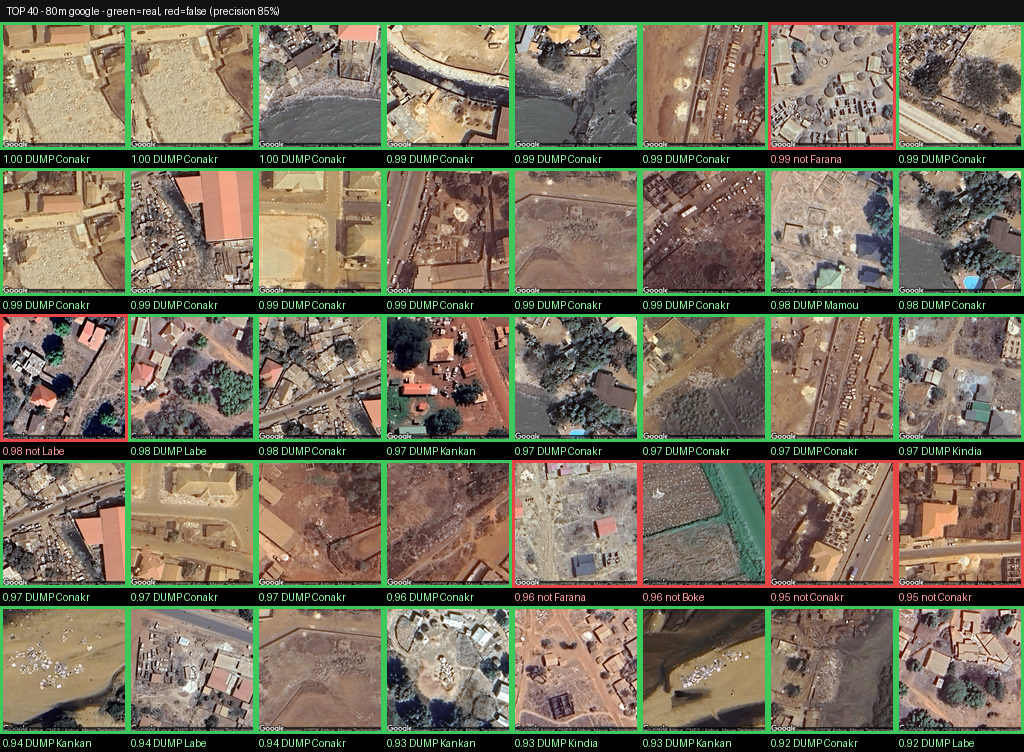

**google — missed**

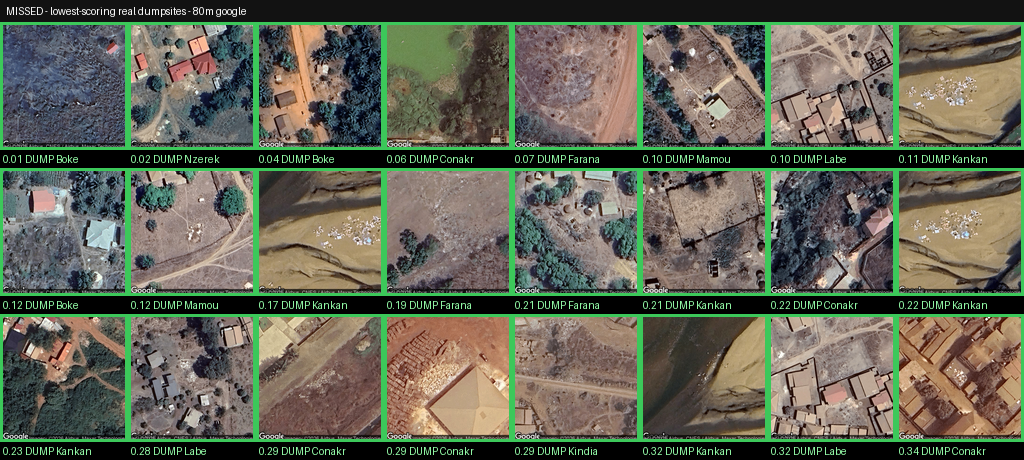

**esri — flagged**

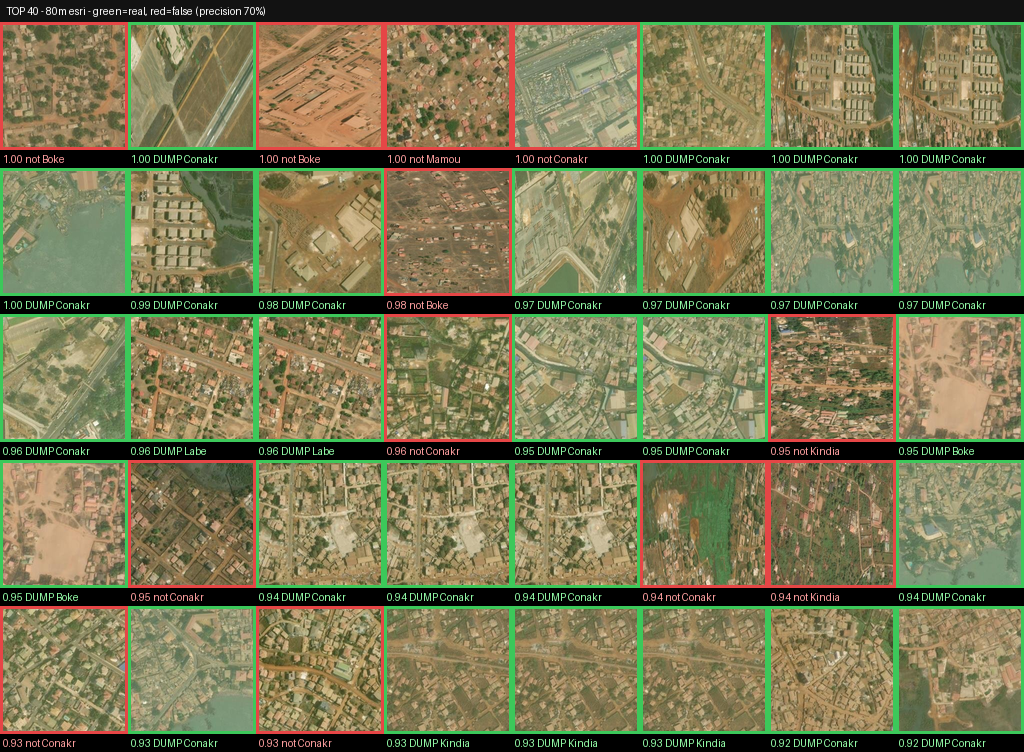

**esri — missed**

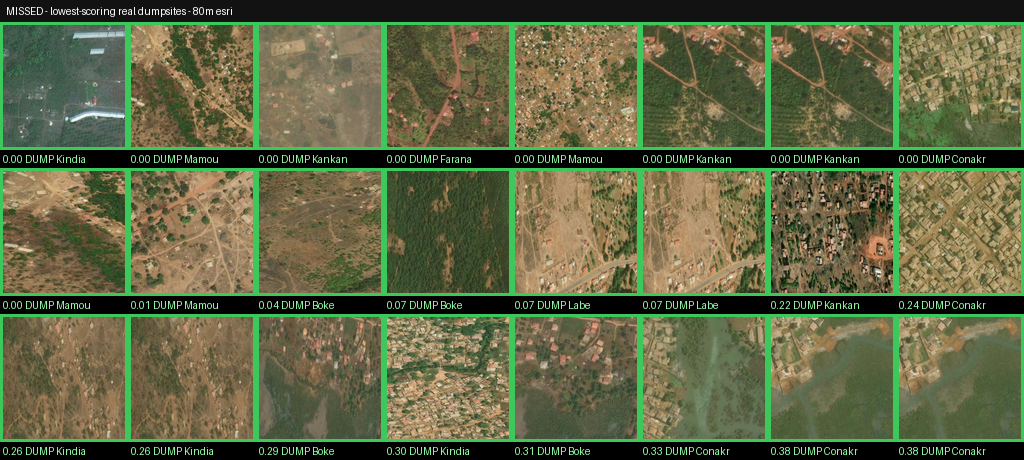

In [9]:
from IPython.display import Image, display, Markdown
for src in ("google", "esri"):
    for kind in ("flagged", "missed"):
        p = REG / f"results_pt80_{src}_{kind}.png"
        if p.exists():
            display(Markdown(f"**{src} — {kind}**"))
            display(Image(filename=str(p), width=1000))

---
## 8. Operating point and deployment cost

### The prevalence correction — do not skip this

The evaluation set's prevalence (~17%) is a **sampling artefact**: negatives
were drawn one per 250 m cell, positives one per dump pin. A real sliding 80 m
scan has **~2% prevalence**. Quoting evaluation-set precision as a deployment
figure overstates the model roughly fourfold.

In [10]:
m = metrics("google") or metrics("esri")
op = pd.DataFrame(m["operating_points"])
p = m["deploy_prevalence"]
op["precision_deploy"] = (p * op.recall) / (p * op.recall + (1 - p) * op.fpr)
op = op.rename(columns={"precision_eval": "precision_eval(17%)",
                        "precision_deploy": "precision_deploy(2%)"})
print(f"source = {m['source']}, deployment prevalence = {p:.3f}")
op.round(3)

source = google, deployment prevalence = 0.021


,threshold,recall,fpr,precision_eval(17%),precision_deploy(2%)
0,0.50,0.631,0.113,0.534,0.105
1,0.60,0.595,0.091,0.574,0.121
2,0.70,0.523,0.059,0.644,0.157
3,0.80,0.450,0.031,0.746,0.231
4,0.90,0.324,0.011,0.857,0.381
5,0.95,0.234,0.007,0.867,0.400


### Two-stage cascade

Scoring every 80 m window nationally means millions of tile requests. Screening first with the free Esri
250 m model, and scoring 80 m windows only inside the cells it keeps, restores most of the prevalence and,
for a licensed stage 2, most of the cost.

The screen is fitted and measured (§10). At its 0.30 threshold, on the 595 labelled cells with blocked CV:

| stage-1 threshold | cells kept | positives retained |
|---|---|---|
| **0.30 (shipped)** | **31.6%** | **85.5%** |

With a licensed Google stage 2, the 89,336-cell settled footprint would need roughly **276,000–404,000**
billable requests, about **$530–790** per national scan (the range depends on how clustered the kept cells
are, since adjacent cells share windows). With the free Esri stage 2 (Part 3) the scan costs nothing in
imagery.

**The screen's 14.5% loss is permanent.** Stage 2 never sees those sites, so end-to-end recall is stage 1's
85.5% multiplied by stage 2's recall at whichever tier is displayed — not the tier's recall alone.

Rescans are **imagery-driven, not calendar-driven**: Esri's imagery over these towns is 17–19 months old and
unchanged, so re-scoring monthly would re-download identical pixels twelve times a year. The trigger should
be a cheap monthly imagery-freshness check, re-scanning only where imagery actually changed.

---
## 9. What the point-centred evaluation supports

**Established**

* National scan footprint defined from a published standard (GHSL SMOD), 89,336 cells, overnight on CPU.
* 595 randomly sampled labelled cells across all 8 regions, 111 dump pins.
* At an 80 m point-centred footprint the model separates dumps from residential land (§6).
* Google z19 significantly better than free Esri z17 (ΔAP +0.144, P = 0.004), with both tracks archived
  and reproducible.

**Not established here:** how the model performs on a blind grid, where it must find the dumps itself.
That is §12–§14 and Parts 2–3, and those figures — not these — describe the deployed scan.

**Known limitations to carry into the methodology**

1. Ground truth is photo-interpretation, not field survey.
2. 111 positive examples is a small training set; all intervals are wide.
3. Cross-region transfer is weak — a model fitted on one region does not transfer well to another, so
   national claims rest on the sample spanning all 8 regions rather than on demonstrated generalisation.
4. Detections carry an `imagery_date` that may be 17–19 months old. A "new" detection means newly
   detected, not newly appeared.

---
## 10. Freezing the deployable model

Everything above is *measurement* — cross-validation, which trains and discards a model per fold. Deployment
needs a model saved to disk. `freeze` fits on all the data, with `C` chosen by the same blocked inner CV the
evaluation used, so the shipped model is regularised the way the measured one was.

**The cascade has two stages, and stage 2 has one head per imagery source:**

* `probe_screen.joblib` — stage 1, 250 m cells, **free Esri**. This is the settlement-level model of §3b.
  Its only job is to discard empty country cheaply, so it is judged on recall, not precision.
* `probe_esri.joblib` — stage 2, 80 m windows, **free Esri z17**. The deployed configuration.
* `probe.joblib` — stage 2, 80 m windows, **licensed Google z19**. Opt-in; not enabled on the platform.

A stage-2 head is fitted to one provider's colour processing, compression and capture dates, so a head is
only ever used with its own source (Part 2.5).

The metadata stores the **held-out** metrics from the evaluation run, never numbers from the fit itself — a
model scored on its own training data would look far better than it is.

In [11]:
import json
MODELS = TOOL / "dumpsite_tool" / "models"

rows = []
for f, role in [("probe_screen_meta.json", "1 — screen"),
                ("probe_esri_meta.json",   "2 — confirm, Esri (default)"),
                ("probe_meta.json",        "2 — confirm, Google (opt-in)")]:
    p = MODELS / f
    if not p.exists():
        print(f"MISSING {f} — run: 08_point_model.py freeze / freeze-screen")
        continue
    m = json.loads(p.read_text(encoding="utf-8"))
    h = m.get("held_out_metrics", m)
    rows.append({
        "stage": role,
        "file": f.replace("_meta.json", ".joblib"),
        "imagery": f"{m['source']} z{m['zoom']}",
        "footprint": f"{m['tile_m']:.0f} m",
        "n_train": m["n_train"], "n_pos": m["n_pos"], "C": m["C"],
        "ROC-AUC": round(h.get("roc_auc", m.get("held_out_roc_auc", float("nan"))), 3),
        "avg precision": round(h["avg_precision"], 3) if "avg_precision" in h else "—",
    })
pd.DataFrame(rows).set_index("stage")

,file,imagery,footprint,n_train,n_pos,C,ROC-AUC,avg precision
stage,,,,,,,,
1 — screen,probe_screen.joblib,esri z17,250 m,595,55,0.001,0.856,—
"2 — confirm, Esri (default)",probe_esri.joblib,esri z17,80 m,651,111,0.001,0.832,0.543
"2 — confirm, Google (opt-in)",probe.joblib,google z19,80 m,651,111,0.010,0.911,0.696


In [12]:
# What the screen costs us, measured rather than assumed.
s = json.loads((MODELS / "probe_screen_meta.json").read_text(encoding="utf-8"))
c = json.loads((MODELS / "probe_meta.json").read_text(encoding="utf-8"))
keep, s_rec = s["cells_kept_at_threshold"], s["site_recall_at_threshold"]

print(f"stage 1 at threshold {s['screen_threshold']}:")
print(f"  keeps {keep:.1%} of cells  ->  that is the cost saving")
print(f"  retains {s_rec:.1%} of sites  ->  {1-s_rec:.1%} are lost before stage 2 sees them")
print("\nEnd-to-end recall by display tier (stage 1 x stage 2, NOT stage 2 alone):")
ops = {o["threshold"]: o for o in c["held_out_metrics"]["operating_points"]}
for tier, thr in sorted(c["tiers"].items(), key=lambda kv: -kv[1]):
    r2 = ops[thr]["recall"]
    print(f"  {tier:<7} thr {thr:.2f}   stage2 {r2:.1%}  x {s_rec:.1%}  =  {r2*s_rec:.1%} of sites found")

stage 1 at threshold 0.3:
  keeps 31.6% of cells  ->  that is the cost saving
  retains 85.5% of sites  ->  14.5% are lost before stage 2 sees them

End-to-end recall by display tier (stage 1 x stage 2, NOT stage 2 alone):
  high    thr 0.90   stage2 32.4%  x 85.5%  =  27.7% of sites found
  medium  thr 0.70   stage2 52.3%  x 85.5%  =  44.6% of sites found
  all     thr 0.50   stage2 63.1%  x 85.5%  =  53.9% of sites found


---
## 11. The interface the platform calls

The backend does **not** import the model. It calls one function:

```python
plasticwaste_tool.detection.classify_dumpsite_candidates(bounds, tier=..., confirm_source=..., budget=...)
```

which returns a GeoDataFrame with a fixed schema. That keeps the developers' surface one function wide, so
the model behind it can change without touching their code (`docs/GEDH_Integration_Deployment_Plan.md`).

Four properties of this function are deliberate and worth seeing run:

1. **It returns a correctly typed empty layer while disabled** (`PW_DUMPSITE_ENABLED`, off by default), so
   the UI can be built and tested before the scan is switched on.
2. **Stage-2 imagery is chosen by `confirm_source`** — `"esri"` (default, free, `probe_esri.joblib`) or
   `"google"` (licensed, `probe.joblib`). The scan refuses a head that does not match its source.
3. **It refuses a Google scan without an explicit `budget`.** A Google stage 2 bills per 80 m window; a
   task that forgets the cap is a four-figure bill. An Esri scan bills nothing and needs no budget.
4. **The tier is a display filter, not a model change.** Every candidate is scored identically and kept;
   the tier only decides what is returned, so it can be retuned later without re-scanning.

In [13]:
import plasticwaste_tool.config as PWCFG
import plasticwaste_tool.detection as PWDET

empty = PWDET.classify_dumpsite_candidates()          # disabled -> typed, empty
print("disabled ->", len(empty), "rows, columns:")
print("  " + ", ".join(empty.columns))

PWCFG.DUMPSITE_MODEL_CONFIG["enabled"] = True         # enable for this session
for kwargs, what in [({}, "no bounds"),
                     ({"bounds": (-13.58, 9.65, -13.56, 9.66),
                       "confirm_source": "google"}, "google without budget"),
                     ({"bounds": (-13.58, 9.65, -13.56, 9.66),
                       "budget": 0, "tier": "maybe"}, "unknown tier")]:
    try:
        PWDET.classify_dumpsite_candidates(**kwargs)
        print(f"  !! {what}: NO GUARD")
    except ValueError as e:
        print(f"  guard holds ({what}): {str(e).split('.')[0][:78]}")

disabled -> 0 rows, columns:
  geometry, confidence, tier, area_ha, n_windows, status, detection_date, imagery_date, model_version, material_flags, toxicity_flag
  guard holds (no bounds): classify_dumpsite_candidates() needs bounds=(minx, miny, maxx, maxy) in EPSG:4
  guard holds (google without budget): classify_dumpsite_candidates() requires an explicit budget: the cap on billabl
  guard holds (unknown tier): tier must be one of ['all', 'high', 'medium'], got 'maybe'


---
## 12. Running the cascade on real imagery

Everything to this point was measured on **point-centred crops** — windows
placed on coordinates a human had already chosen. Deployment is different: the
model sees a blind grid and must decide where the dumps are. Nothing above
tests that.

This section scans a **1.9 × 0.9 km box over Conakry** containing four cells
labelled positive, so the result can be checked against pins the labeller
placed rather than against the model's own opinion.

> **This costs no quota.** The tiles were fetched once into
> `manual_qa/scan_demo_cache/` and every cell below calls the cascade with
> `budget=0`, which serves cached tiles and issues **zero** billable requests.
> Re-run this notebook as often as you like.
>
> Those cached tiles are retained Google Maps imagery: they stay local and must
> **never** be committed to the repository.

The stages are run explicitly rather than through one call, so each one's
output is visible.

In [14]:
import plasticwaste_tool.dumpsite_tool.scan as SCAN
import logging
logging.basicConfig(level=logging.INFO, force=True)
logging.getLogger("plasticwaste_tool").setLevel(logging.WARNING)

AOI   = (-13.5763, 9.6519, -13.5591, 9.6602)   # the 4-positive Conakry cluster
CACHE = MQ / "scan_demo_cache"
print("AOI  :", AOI)
print("cache:", CACHE, "(exists)" if CACHE.exists() else "(MISSING - needs a paid fetch)")

screen, screen_meta = SCAN.load_head("probe_screen.joblib")
confirm, confirm_meta = SCAN.load_head("probe.joblib")
tiers, default_tier = SCAN.read_tiers()
print("tiers:", tiers, "| default:", default_tier)

AOI  : (-13.5763, 9.6519, -13.5591, 9.6602)
cache: c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\plasticwaste_tool\manual_qa\scan_demo_cache (exists)
tiers: {'high': 0.9, 'medium': 0.7, 'all': 0.5} | default: high


In [15]:
# --- stage 1: free Esri screen over 250 m cells ---------------------------
import plasticwaste_tool.dumpsite_tool.inference as GI
import plasticwaste_tool.dumpsite_tool.features as BM

cells  = SCAN._windows(AOI, SCAN.SCREEN_TILE_M)
paths1, _ = GI.fetch_tiles_esri(cells, CACHE / "screen", size_px=800, zoom=SCAN.SCREEN_ZOOM)
cells["score"] = SCAN._score(paths1, screen)
kept = cells[cells.score >= SCAN.SCREEN_THRESHOLD]

print(f"{len(cells)} cells scored; {len(kept)} kept at threshold {SCAN.SCREEN_THRESHOLD}"
      f"  ({len(kept)/len(cells):.0%})")
print("\nDense Conakry keeps almost everything - that is the screen behaving as")
print("designed. Nationally it keeps 31.6%; here there is simply no empty country")
print("to discard, so this AOI tests stage 2, not the screen's economics.")

42 cells scored; 40 kept at threshold 0.3  (95%)

Dense Conakry keeps almost everything - that is the screen behaving as
designed. Nationally it keeps 31.6%; here there is simply no empty country
to discard, so this AOI tests stage 2, not the screen's economics.


In [16]:
# --- stage 2: Google confirm at 80 m, inside kept cells only --------------
win    = SCAN._windows_for_cells(kept, SCAN.CONFIRM_TILE_M)
paths2 = GI.fetch_tiles_google(win, CACHE / "confirm", size_px=800,
                               zoom=SCAN.CONFIRM_ZOOM, budget=0)   # 0 = cache only
win["path"]  = paths2
win["score"] = SCAN._score(paths2, confirm)

got = win.score.notna().sum()
print(f"{len(win)} windows; {got} scored from cache; {len(win)-got} unavailable")
print("\nscore distribution of the scored windows:")
print(win.score.describe().round(3).to_string())
for t, thr in sorted(tiers.items(), key=lambda kv: -kv[1]):
    print(f"  >= {thr:.2f} ({t:<6}) : {(win.score >= thr).sum():4d} windows")

422 windows; 422 scored from cache; 0 unavailable

score distribution of the scored windows:
count    422.000
mean       0.500
std        0.328
min        0.002
25%        0.199
50%        0.466
75%        0.847
max        1.000
  >= 0.90 (high  ) :   77 windows
  >= 0.70 (medium) :  140 windows
  >= 0.50 (all   ) :  200 windows


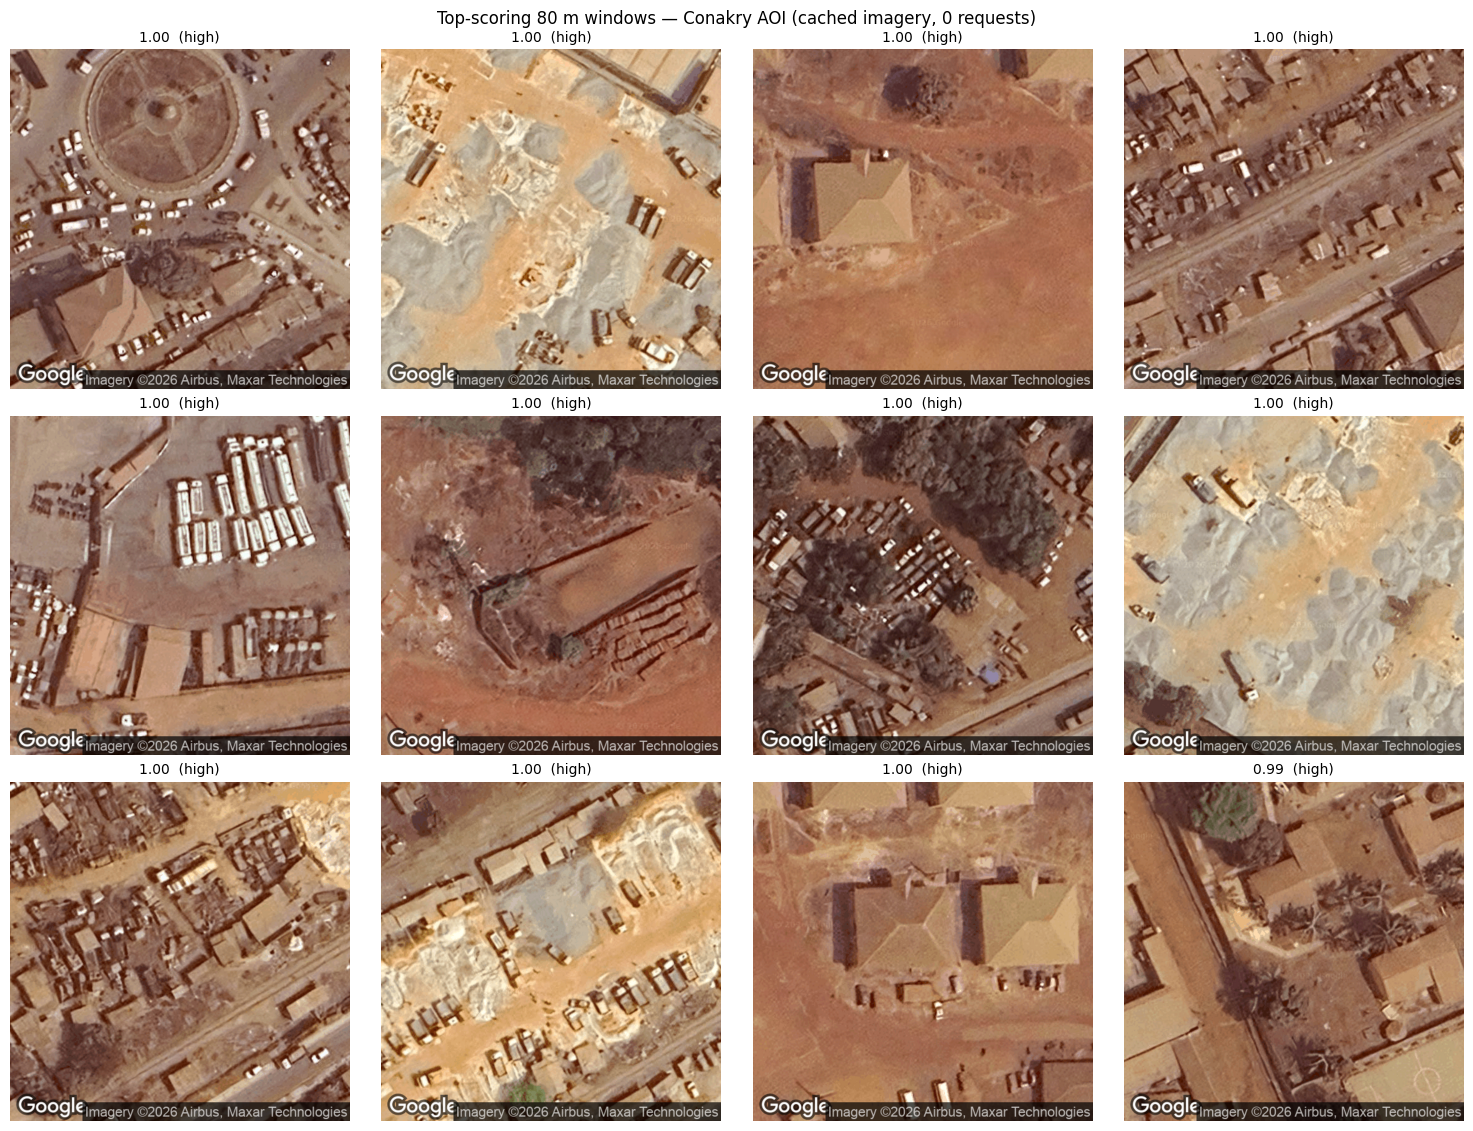

In [17]:
# --- what the model calls a dumpsite: the highest-scoring windows ---------
import matplotlib.pyplot as plt
from PIL import Image as PILImage

top = win[win.score.notna()].nlargest(12, "score")
fig, axes = plt.subplots(3, 4, figsize=(15, 11.5))
for ax, (_, r) in zip(axes.ravel(), top.iterrows()):
    ax.imshow(PILImage.open(r.path)); ax.axis("off")
    tier = SCAN._tier_of(r.score, tiers) or "below all"
    ax.set_title(f"{r.score:.2f}  ({tier})", fontsize=10)
for ax in axes.ravel()[len(top):]:
    ax.axis("off")
fig.suptitle("Top-scoring 80 m windows — Conakry AOI (cached imagery, 0 requests)",
             fontsize=12)
plt.tight_layout(); plt.show()

In [18]:
# --- the packaged output the platform receives ----------------------------
gdf = PWDET.classify_dumpsite_candidates(AOI, cache_dir=str(CACHE), budget=0,
                                         tier="all")
print(f"{len(gdf)} candidate sites at tier 'all' (>= {tiers['all']})")
if len(gdf):
    for t, thr in sorted(tiers.items(), key=lambda kv: -kv[1]):
        print(f"  {t:<7} (>= {thr:.2f}): {(gdf.confidence >= thr).sum()} sites")
    display(gdf.drop(columns="geometry")
               .sort_values("confidence", ascending=False)
               .head(15).round(3))

33 candidate sites at tier 'all' (>= 0.5)
  high    (>= 0.90): 2 sites
  medium  (>= 0.70): 17 sites
  all     (>= 0.50): 33 sites


c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\plasticwaste_tool\dumpsite_tool\scan.py:300: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  merged = unary_union(grp.geometry.buffer(1e-6))


,confidence,tier,area_ha,n_windows,status,detection_date,imagery_date,model_version,material_flags,toxicity_flag
32,0.994,high,43.562,68,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
31,0.986,high,5.772,9,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
9,0.899,medium,9.626,15,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
11,0.897,medium,9.622,15,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
14,0.893,medium,0.644,1,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
12,0.888,medium,1.927,3,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
8,0.880,medium,1.927,3,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
3,0.850,medium,5.772,9,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
2,0.844,medium,3.851,6,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
13,0.840,medium,0.644,1,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None


In [19]:
# --- do the polygons land on the dumps the LABELLER marked? ---------------
# The honest test: distance from each labelled pin to the nearest candidate.
from shapely.geometry import Point

pts = pd.read_csv(MQ / "_point_samples.csv")
inside = pts[(pts.lon > AOI[0]) & (pts.lon < AOI[2]) &
             (pts.lat > AOI[1]) & (pts.lat < AOI[3])]
pins = inside[inside.label == 1]
print(f"{len(inside)} labelled samples in this AOI, {len(pins)} of them dump pins\n")

if len(gdf) and len(pins):
    import numpy as np
    M_PER_DEG = 111_000.0
    rec = []
    for _, p in pins.iterrows():
        pt = Point(p.lon, p.lat)
        d  = gdf.geometry.distance(pt) * M_PER_DEG          # degrees -> ~metres
        k  = int(np.argmin(d.values))
        rec.append({"pin": p.sid, "hit": bool(d.min() == 0),
                    "dist_m": round(float(d.min()), 1),
                    "nearest_conf": round(float(gdf.iloc[k].confidence), 3),
                    "nearest_tier": gdf.iloc[k].tier})
    r = pd.DataFrame(rec)
    display(r)
    print(f"\npins falling INSIDE a candidate polygon: {r.hit.sum()}/{len(r)}")
    print("A miss here is not automatically a model failure: the labeller marked")
    print("cells they were unsure about (most positives are 'medium' or 'low'),")
    print("so some pins may not be dumpsites at all.")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_18588\3781517720.py:17: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  d  = gdf.geometry.distance(pt) * M_PER_DEG          # degrees -> ~metres


5 labelled samples in this AOI, 5 of them dump pins



,pin,hit,dist_m,nearest_conf,nearest_tier
0,nat_cona_0067_p0,True,0.0,0.994,high
1,nat_cona_0067_p1,True,0.0,0.994,high
2,nat_cona_0057_p0,True,0.0,0.994,high
3,nat_cona_0037_p0,False,24.3,0.512,all
4,nat_cona_0072_p0,True,0.0,0.850,medium



pins falling INSIDE a candidate polygon: 4/5
A miss here is not automatically a model failure: the labeller marked
cells they were unsure about (most positives are 'medium' or 'low'),
so some pins may not be dumpsites at all.


### What the unlabelled scan shows

| | measured |
|---|---|
| windows scoring ≥ 0.90 (`high`) | 77 of 422 — 18% |
| windows scoring ≥ 0.50 (`all`) | 200 of 422 — 47% |

Four of the five labelled pins fall inside a candidate polygon, but that is not a hit rate: when a large
share of the AOI is flagged, hitting a pin is likely by chance, and the pins say nothing about the windows
between them.

Accuracy on a blind grid can only be measured against a grid labelled window by window. That is §14.

---
## 13. What this module delivers to the platform

Checked against the Hub SRS (`docs/SRS_GuineaDigitalHub_v2.docx`, GEDH-FR-0501
to 0507), not against the UI mock-up alone. The mock shows six plastic layers;
**three come from this repository**, and two of those are the same FDI product
under different geographic filters.

| UI layer | SRS | Produced here? | Source |
|---|---|---|---|
| Open dumpsites | FR-0503 | **yes** | this notebook |
| River plastic index | FR-0503 | **yes** | FDI, filtered to rivers |
| Coastal risk areas | FR-0503 | **yes** | FDI, filtered to coast |
| Waste collection points | FR-0505/6 | no | Collector PWA — separate system |
| Recycling facilities | FR-0504 | no | partner registry |
| Urban waste density | **not in SRS** | no | would have to be defined |

**FR-0504** wants each popup to carry location name, detection date, area (ha),
material distribution and a toxicity flag. The schema already carries
`detection_date` and `area_ha`; `material_flags` and `toxicity_flag` are
present but `None`, pending the plastic-characterisation component, so the UI
can be built against the final shape now. A **location name** still needs an
admin-boundary join — small, and not yet done.

**FR-0503** asks for colour-coding by "concentration level". Dumpsites have no
concentration measure; the sensible ramp is the **confidence tier**.

### What is honest to publish

`status` is `unverified` on every polygon. These are photo-interpreted
candidates from a model whose own ground truth was photo-interpretation, never
a field survey, and `imagery_date` can be well over a year older than
`detection_date`. A new row means **newly detected, not newly appeared**. The
defensible wording is *"AI-detected dumpsite candidates, not field-verified"*.

---
## 14. Blind-grid accuracy

Everything before §12 scored **point-centred crops**: a window placed on a coordinate a human had already
chosen. Deployment scores a **blind grid**. These are different tasks and deserve separate numbers; quoting
the first as if it were the second is the single most misleading thing this project could publish.

All 422 windows of the §12 AOI were labelled by hand — **110 positive, 312 negative** — and the cell below
measures the frozen Google head against them.

In [20]:
import json
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

lab = pd.DataFrame([f["properties"] for f in
                    json.loads((REG / "conakry_blindgrid_review.geojson")
                               .read_text(encoding="utf-8"))["features"]])
lab["y"] = lab.label.astype(int)
sc = pd.read_csv(RUNS / "cascade_demo_conakry" / "windows_scored.csv")
g = lab.merge(sc[["tile_id", "score"]], on="tile_id")

print(f"{len(g)} hand-labelled windows, {g.y.sum()} positive "
      f"({g.y.mean():.0%} base rate)\n")

rows = []
for name, s in [("all 422", g), ("east (held out)", g[g.half == "east"]),
                ("west (training half)", g[g.half == "west"])]:
    rows.append({"subset": name, "n": len(s), "pos": int(s.y.sum()),
                 "ROC-AUC": round(roc_auc_score(s.y, s.score), 3),
                 "avg precision": round(average_precision_score(s.y, s.score), 3)})
display(pd.DataFrame(rows).set_index("subset"))

op = []
for thr in (0.90, 0.70, 0.50, 0.30):
    f = g.score >= thr
    tp = int((f & (g.y == 1)).sum()); fp = int((f & (g.y == 0)).sum())
    fn = int((~f & (g.y == 1)).sum())
    op.append({"threshold": thr, "flagged": int(f.sum()), "TP": tp, "FP": fp,
               "precision": round(tp / max(tp + fp, 1), 3),
               "recall": round(tp / max(tp + fn, 1), 3)})
print("operating points on the blind grid "
      f"(no-skill precision = base rate = {g.y.mean():.3f}):")
display(pd.DataFrame(op))

422 hand-labelled windows, 110 positive (26% base rate)



,n,pos,ROC-AUC,avg precision
subset,,,,
all 422,422,110,0.682,0.476
east (held out),220,61,0.692,0.485
west (training half),202,49,0.665,0.474


operating points on the blind grid (no-skill precision = base rate = 0.261):


,threshold,flagged,TP,FP,precision,recall
0,0.9,77,45,32,0.584,0.409
1,0.7,140,61,79,0.436,0.555
2,0.5,200,72,128,0.360,0.655
3,0.3,270,88,182,0.326,0.800


### Reading that table

**ROC-AUC 0.682 / AP 0.476 on the blind grid, against 0.911 / 0.696 on point-centred crops.** Both are
real; they answer different questions.

At the `high` tier the model flags 77 windows and 45 of them are genuine — precision 0.58 against a base
rate of 0.26, roughly **2.2× better than chance**. That is a usable screening layer, not the authoritative
map the 0.911 figure would imply.

**One caveat travels with this number.** This AOI was chosen *because* it contained a cluster of labelled
dumps, so its 26% base rate is enriched. Part 2 adds a second, blindly chosen AOI.

### Training-data variants tested (not adopted)

The training set holds 43% of its positives in Conakry against 9% of its negatives, and only 50 urban
negatives. Three training mixtures were therefore compared on the held-out east half of this grid
(220 windows, 61 positive), with `C` tuned separately for each:

| variant | training rows | ROC-AUC | avg precision |
|---|---|---|---|
| shipped (rural-heavy base) | 651 | 0.692 | 0.485 |
| base + urban west half | 853 | 0.688 | 0.504 |
| urban west half only | 202 | 0.747 | 0.555 |

Adding urban windows changes nothing (ΔROC-AUC −0.004). The urban-only variant leads by +0.055, but a paired
block bootstrap over 34 spatial blocks puts that at 95% CI [−0.048, +0.143] (P = 0.28), and it was trained
on the neighbourhood beside the one it is tested on. The shipped head therefore stays; only a blind grid in
another town could show a variant is better.

Reproduce with `python 08_point_model.py retrain-urban`, `retrain-variants` and `bootstrap-variants`
(features are cached; no imagery is fetched).

---

# Part 2 — Replication at Boké, and what the model responds to

Part 1 measures the model in **one** place: a 1.9 × 0.9 km area of Conakry, chosen because it contained
known dumps. Before anything is deployed nationally, a second blind grid has to be labelled somewhere
else. This part is that test, and the diagnostics its labels make possible.

| step | script | what it answers |
|---|---|---|
| 1 | `26_blind_grid_protocol.py evaluate` | does the Conakry figure replicate? |
| 2 | `27_blindgrid_diagnostics.py` | is the model responding to *waste*? |
| 3 | `28_architecture_ablation.py` | would a better architecture fix it? (summarised in 2.3) |

Every cell below reads artefacts already on disk. **Nothing here spends money.**

## 2.1 A second blind grid, at Boké

**557 contiguous 80 m windows** over Boké — an inland mining town 250 km from
Conakry, not selected for known dump density — exhaustively hand-labelled
without the model's scores visible.

The pass criterion was fixed **in code** (`26_blind_grid_protocol.py`,
`PASS_CRITERION`) before the imagery was purchased. It is scored below exactly
as declared, not as chosen after seeing the answer.

In [21]:
run(["26_blind_grid_protocol.py", "evaluate", "--town", "boke"])

$ c:\Users\ASUS\AppData\Local\Programs\Python\Python310\python.exe 26_blind_grid_protocol.py evaluate --town boke

BLIND GRID â€” boke
  windows 557   positive 243   base rate 0.436
  ROC-AUC 0.738   average precision 0.640 (no-skill baseline = base rate, 0.436)

  tier      flagged   true  precision   recall    lift
  high           76     49      0.645    0.202    1.48x
  medium        173    110      0.636    0.453    1.46x
  all           249    153      0.614    0.630    1.41x

  Conakry, for comparison:
  windows 422   positive 110   base rate 0.261
  ROC-AUC 0.682   average precision 0.477
  high        77     45      0.584    0.409   2.24x

  End-to-end recall at 'high': 0.855 x 0.202 = 17.2% of sites present.

  PRE-DECLARED CRITERION (fixed before this grid existed):
    [pass] windows >= 250
    [pass] positives >= 20
    [FAIL] lift >= 1.5x
    [pass] precision@high >= 0.35

  Criterion NOT met. Do not publish a national layer.

  Base-rate-invariant comparison (ROC-AUC is 

CompletedProcess(args=['c:\\Users\\ASUS\\AppData\\Local\\Programs\\Python\\Python310\\python.exe', '26_blind_grid_protocol.py', 'evaluate', '--town', 'boke'], returncode=2, stdout="\nBLIND GRID â€” boke\n  windows 557   positive 243   base rate 0.436\n  ROC-AUC 0.738   average precision 0.640 (no-skill baseline = base rate, 0.436)\n\n  tier      flagged   true  precision   recall    lift\n  high           76     49      0.645    0.202    1.48x\n  medium        173    110      0.636    0.453    1.46x\n  all           249    153      0.614    0.630    1.41x\n\n  Conakry, for comparison:\n  windows 422   positive 110   base rate 0.261\n  ROC-AUC 0.682   average precision 0.477\n  high        77     45      0.584    0.409   2.24x\n\n  End-to-end recall at 'high': 0.855 x 0.202 = 17.2% of sites present.\n\n  PRE-DECLARED CRITERION (fixed before this grid existed):\n    [pass] windows >= 250\n    [pass] positives >= 20\n    [FAIL] lift >= 1.5x\n    [pass] precision@high >= 0.35\n\n  Criterio

### Read that verdict carefully — the headline misleads on its own

The criterion is **missed**: lift 1.48× against a required 1.5×. So no national
layer. But that is *not* because the model got worse.

**ROC-AUC went up, 0.682 → 0.738.**

Lift is precision ÷ base rate, so it is capped at 1/base-rate — 3.83× where
prevalence is 26%, but only **2.29×** where it is 44%. Boké simply has more
waste in it, so the same performance is scored against a lower ceiling.
Choosing lift instead of a prevalence-invariant measure was a flaw in the
criterion. It is recorded as `known_defect` in the script rather than quietly
swapped, because changing a criterion after seeing the result is precisely the
freedom that declaring it in advance exists to remove.

So the Conakry figure **did** replicate. Which raises the sharper question,
and one a blind grid cannot answer on its own:

> An ROC-AUC near 0.7 is equally consistent with a model that detects waste
> imperfectly, and one that detects something merely *correlated* with waste
> and never sees waste at all.

Those two readings imply opposite deployment decisions.

## 2.2 The Boké labels can settle it, because they are not just ticks

The annotator did more than mark each window 0 or 1. Every positive window
carries **hand-digitised point coordinates for each waste feature visible in
it** — 752 points across 243 windows, up to nine in a single window, stored
semicolon-separated in the `lat` / `long` fields.

That turns the grid from a label set into a record of *quantity and position*,
and quantity is what any genuine detector must be sensitive to:

> Among windows that contain waste, a model that sees waste must score a window
> holding nine waste features above one holding a single feature.

This is a **dose-response** test. It is confined entirely to the positive
class — it never compares positives against negatives — so it is immune to
every question about where the class boundary was drawn, and to how confident
the annotator was in drawing it.

On that second point, stated plainly because it matters: nearly every positive
is annotated *"could be dumpsite"* at medium confidence. **That is not
hedging to be discounted.** It is an accurate report of what overhead imagery
can support at this scale. The protocol's own instruction, *"1 = waste
visible"*, asked for a certainty the imagery cannot deliver — a flaw in the
protocol, not in the labelling. The labels are used below exactly as given.

In [22]:
run(["27_blindgrid_diagnostics.py", "--town", "boke"])

$ c:\Users\ASUS\AppData\Local\Programs\Python\Python310\python.exe 27_blindgrid_diagnostics.py --town boke
BLIND GRID DIAGNOSTICS - boke
  557 windows, 243 positive, 752 digitised waste points
  ROC-AUC 0.738  AP 0.640  base rate 0.436
  ! 3 point entries lie >200 m from their own tile (data-entry slips). Excluded from geometry; labels untouched.

  TEST 1 - does the score rise with the amount of waste?
    1 point      n=  59 mean=0.613 median=0.697 >=high=20%
    2-3 points   n= 104 mean=0.590 median=0.655 >=high=17%
    4-6 points   n=  64 mean=0.585 median=0.702 >=high=23%
    7+ points    n=  15 mean=0.505 median=0.437 >=high=27%
    Spearman rho=-0.027 P=0.676  ->  NO DOSE-RESPONSE

  TEST 2 - does a central target score higher?
    <20 m  n=  85 mean=0.557
    >=20 m n= 157 mean=0.607
    P=0.392  ->  NO CENTRALITY EFFECT

  TEST 3 - what the score tracks (notes = grouping only):
    forest                 n=  83 pos=   0 mean=0.004 >=high= 0.0%
    water                  n=  27

CompletedProcess(args=['c:\\Users\\ASUS\\AppData\\Local\\Programs\\Python\\Python310\\python.exe', '27_blindgrid_diagnostics.py', '--town', 'boke'], returncode=0, stdout='BLIND GRID DIAGNOSTICS - boke\n  557 windows, 243 positive, 752 digitised waste points\n  ROC-AUC 0.738  AP 0.640  base rate 0.436\n  ! 3 point entries lie >200 m from their own tile (data-entry slips). Excluded from geometry; labels untouched.\n\n  TEST 1 - does the score rise with the amount of waste?\n    1 point      n=  59 mean=0.613 median=0.697 >=high=20%\n    2-3 points   n= 104 mean=0.590 median=0.655 >=high=17%\n    4-6 points   n=  64 mean=0.585 median=0.702 >=high=23%\n    7+ points    n=  15 mean=0.505 median=0.437 >=high=27%\n    Spearman rho=-0.027 P=0.676  ->  NO DOSE-RESPONSE\n\n  TEST 2 - does a central target score higher?\n    <20 m  n=  85 mean=0.557\n    >=20 m n= 157 mean=0.607\n    P=0.392  ->  NO CENTRALITY EFFECT\n\n  TEST 3 - what the score tracks (notes = grouping only):\n    forest        

### What that found

Three results, one conclusion.

**1. No dose-response.** ρ = −0.027, P = 0.68. Nine times the waste produces no
rise in score.

**2. No centrality effect.** P = 0.39. Waste at the centre of the window scores
no higher than waste at its edge.

**3. The ordering by land cover** — the part that makes the diagnosis concrete:

| window contains | n | mean score | ≥ high tier |
|---|---|---|---|
| forest | 83 | 0.004 | 0% |
| water | 27 | 0.013 | 0% |
| bare / sparse | 14 | 0.152 | 0% |
| quarry / borrow pit | 3 | 0.350 | 0% |
| settlement, **no** waste | 178 | 0.496 | 12.9% |
| labelled waste | 243 | 0.591 | 20.2% |
| **construction site** | 5 | **0.902** | **80%** |

> The classifier separates **disturbed anthropogenic ground from natural
> cover**, and does that almost perfectly. It does **not** separate waste from
> other disturbed ground.

Waste windows outscore forest because waste sits on bare, accessible,
disturbed ground — not because the waste is visible to the model. Construction
sites, which contain no waste at all, top the table.

The 80 m footprint narrows the margin the 250 m footprint lost (§3b) without
closing it: dumps beat settlement by 0.10, but construction still beats dumps.

*(The notes column is used for grouping in the report only. Every metric —
ROC-AUC, AP, lift, ρ — is computed from `label` and `model_score` alone.)*

## 2.3 Would a better architecture fix it?

One explanation for the missing dose-response is **spatial dilution**: a 14 m dumpsite occupies about 3% of
an 80 m window, and the probe averages features over the whole window. That is the constraint a Feature
Pyramid Network removes — the design of **AerialWaste** (Torres & Fraternali, 2023), the strongest published
model in this area — by carrying earlier, finer layers forward.

It was tested holding everything fixed except the representation (same frozen backbone, windows, labels,
blocked split and probe): three ResNet-50 layers (receptive field ≈ 10, 29 and 48 m), two pooling operators
(average; mean of the 5 strongest positions), and all three layers concatenated.

| representation | ~RF | ROC-AUC | AP | dose ρ |
|---|---|---|---|---|
| shipped (layer 4, average) | 48 m | 0.738 | 0.640 | −0.020 |
| layer 2, average | 10 m | 0.744 | 0.647 | −0.050 |
| layer 3, average | 29 m | 0.720 | 0.637 | −0.010 |
| pyramid, average | — | 0.729 | 0.635 | 0.021 |
| layer 2, top-5 pooling | 10 m | 0.702 | 0.599 | −0.093 |

All eight variants land between 0.68 and 0.74 ROC-AUC, and **none recovers a dose-response** — every ρ is
indistinguishable from zero. Spatial dilution is therefore not the binding constraint: generic ImageNet
features do not encode waste as distinct from disturbed ground at any scale, so a pyramid has nothing to
localise. AerialWaste's features were trained on a large labelled waste corpus; importing the architecture
without that supervision imports the cost and none of the benefit. Two transfers point the same way: a
checkpoint from the Lab's Guatemala project degraded performance on Guinean imagery, and AerialWaste-derived
features did not beat generic ImageNet features.

**The binding constraint is the volume of task-specific labelled data — a data-collection programme, not a
modelling task.**

Reproduce with `python 28_architecture_ablation.py --town boke` (cached feature vectors; no imagery is
fetched).

## 2.4 How this compares with the Lab's Guatemala implementation

A **benchmark**, not a controlled experiment — different countries, imagery,
zoom levels, label protocols and test sets. No causal claim about which design
choice is responsible. It is here to situate the work in the office portfolio.

| | Guatemala | Guinea |
|---|---|---|
| model | Polimi classifier, adapted | ImageNet ResNet-50 + linear probe |
| imagery | Google z18 | Google z19 |
| windows / positives | 208 / 68 | 651 / 111 |
| base rate of test set | 32.7% | 17.1% |
| recall | 0.691 | 0.631 |
| precision **as measured** | 0.681 | 0.534 |
| lift over own base rate | 2.08× | **3.13×** |

Read naively the precision row says Guinea is weaker. **That is an artefact of
the test sets, not a property of the models.** Precision is not an attribute of
a classifier alone — it depends on how common positives are in the data it is
shown. The Guinea set is 17.1% positive against Guatemala's 32.7%, so the
Guinea model is finding needles in roughly twice as much hay.

Recall and false-positive rate *are* invariant to prevalence, so precision can
be recomputed at any base rate by Bayes' rule:

$$\text{precision} = \frac{r\,p}{r\,p + \text{fpr}\,(1-p)}$$

Restating the Guinea model at Guatemala's 32.7% base rate:

| threshold | recall | fpr | precision @ 17.1% | **precision @ 32.7%** |
|---|---|---|---|---|
| 0.50 | 0.631 | 0.113 | 0.534 | **0.731** |
| 0.70 | 0.523 | 0.059 | 0.644 | **0.811** |
| 0.90 | 0.324 | 0.011 | 0.857 | **0.934** |

**At comparable recall (0.63 vs 0.69), prevalence-matched precision is 0.731
against Guatemala's 0.681** — and the margin widens at stricter thresholds.

So: at least comparable, and on a like-for-like basis somewhat better, with a
simpler model. The §2.2 finding is *not* displaced by this — both are
comparisons on the **point-centred** task, and neither shows that either model
detects waste rather than the ground it sits on.

## 2.5 What actually ships: the on-demand location checker

Ruling out the national sweep does not rule out the model. A user dropping a
pin has **already decided** the location is worth asking about — which is the
*point-centred* condition under which **ROC-AUC 0.911** was measured, not the
blind-grid condition.

It is the first of the two terrestrial products the methodology recommends deploying
(§9.3.1; the second is the screening scan of Part 3), wired in the backend at `plasticwaste_api/location-checks/check/`.

### The head must match the imagery source

| head | scored against | point-centred | blind grid |
|---|---|---|---|
| `probe.joblib` | Google z19 | 0.911 | 0.738 |
| `probe_esri.joblib` | Esri z17 | 0.832 | 0.687 |
| `probe.joblib` | **Esri z17 — mismatched** | — | **0.483, i.e. chance** |

A linear probe over frozen features is fitted to one provider's colour
processing, compression and capture dates. Point the Google head at Esri pixels
and it returns near-zero for **everything** — over this grid, mean 0.002, not
one window above any tier. **No exception, no warning.** Matched correctly,
free imagery is a real option rather than a degraded one.

Do not conflate this with the resolution result in §7.2.1 (ΔROC-AUC −0.011,
P = 0.70). That experiment degraded Google imagery *in place*.
**Resolution invariance is not source invariance.**

In [23]:
# Free: three Esri requests, no Google, nothing billed.
import math, pandas as pd
import plasticwaste_tool.dumpsite_tool.scan as SCAN
import plasticwaste_tool.dumpsite_tool.inference as INF

OUT = MQ / "ondemand_demo"; OUT.mkdir(exist_ok=True)

HEAD = "probe_esri.joblib"          # MUST match the source fetched below
model, _ = SCAN.load_head(HEAD)
tiers, _ = SCAN.read_tiers(HEAD)

places = [("waste, hand-labelled",        10.94489, -14.30221),
          ("construction site, no waste", 10.94489, -14.30074),
          ("forest",                      10.94416, -14.29968)]

dlat = 80.0 / 110_574.0
for name, lat, lon in places:
    # Same global lattice the scan uses, anchored at (-180, -90) rather than at
    # the point, so the same ground always gets the same window and tile id.
    j = int(math.floor((lat - SCAN.ORIGIN_LAT) / dlat))
    i = int(math.floor((lon - SCAN.ORIGIN_LON) / SCAN._row_dlon(j, dlat, 80.0)))
    win = SCAN._window(j, i, dlat, 80.0)
    paths, _ = INF.fetch_tiles_esri(pd.DataFrame([win]), str(OUT),
                                 size_px=800, zoom=SCAN.SCREEN_ZOOM)
    s = float(SCAN._score([str(paths[0])], model)[0])
    tier = next((n for n, th in sorted(tiers.items(), key=lambda kv: -kv[1])
                 if s >= th), "below lowest tier")
    print(f"  {name:30s} {win['tile_id']}  {s:.3f}  ({tier})")

print()
print("Three samples are an illustration, not evidence. The aggregate that IS")
print("evidence is the land-cover table in 2.2 and the one below.")

  waste, hand-labelled           r0139523c0226374  0.970  (high)
  construction site, no waste    r0139523c0226376  0.282  (below lowest tier)
  forest                         r0139522c0226378  0.137  (below lowest tier)

Three samples are an illustration, not evidence. The aggregate that IS
evidence is the land-cover table in 2.2 and the one below.


### The land-cover finding survives the source change

Re-scoring all 557 windows on **free Esri with its own head** reproduces the
§2.2 ordering — compressed into a narrower range, but unchanged:

| window contents | n | Esri head | ≥ high tier |
|---|---|---|---|
| water | 27 | 0.232 | 0% |
| forest | 83 | 0.278 | 1% |
| bare / sparse | 14 | 0.374 | 0% |
| settlement, no waste | 178 | 0.544 | 3% |
| **labelled waste** | 242 | **0.583** | 7% |
| quarry / borrow pit | 3 | 0.603 | 0% |
| **construction site** | 5 | **0.757** | **40%** |

Waste again sits barely above settlement; construction again tops the table.
**Two imagery sources, two independently fitted heads, same ordering** — so
this is a property of *what the features represent*, not an artefact of one
provider or one training run. That is the strongest form the §2.2 argument
takes.

### What the interface must say

A user pinning an ordinary built-up block will **not** get a near-zero score:

| what the user pinned | what they will tend to see |
|---|---|
| forest, water, vegetation | very low — **the most reliable output this model produces** |
| ordinary built-up land | mid-range; ~13% reach the high tier |
| construction site, quarry | **high** — the strongest false positive there is |
| actual dumpsite | high, but not separable from the row above |

Present a high score as *"this location resembles sites where waste
accumulates"*, **never** as *"waste detected"*. The API emits `interpretation`
and `confusable_with` on every response for exactly this reason; a client that
strips them is making a claim the evidence does not support.

Exploit the asymmetry rather than apologising for it: a **low** score over
vegetation or water is well-evidenced and can be reported with confidence. It
is the high end that needs the hedge.

**Imagery options** (§9.3.1). Free Esri is the default. Google z19 is
measurably better on identical samples (AP 0.696 vs 0.543, Δ +0.144,
95% CI [+0.036, +0.250], P = 0.004) but bills per request, so it is wired as an
opt-in and is not enabled in the deployed configuration. The gap is **not**
resolution — it is imagery recency. Scores from the two sources are not
interchangeable; store the source with every result.

---

# Part 3 — A free national scan: Esri at stage 2

Parts 1–2 measure the cascade with **licensed Google z19** imagery at stage 2.
The platform cannot buy that imagery (doc 70 D31; the scan endpoint refuses any
`budget > 0`), so the deployed scan confirms on free Esri imagery instead.

Stage 2 can instead confirm on **free Esri z17** imagery, scored with the head
fitted on Esri (`probe_esri.joblib`, point-centred ROC-AUC 0.832 — §2.5 above).
That makes a national scan something the platform can run itself
(`DUMPSITE_MODEL_CONFIG["confirm_source"] = "esri"`, the default).

**Its accuracy is not the Google accuracy and must be measured, not assumed.**
Script 38 scores both hand-labelled blind grids (Conakry 422 windows, Boké 557)
on Esri with the same labels and the same metrics as `26_blind_grid_protocol.py`,
and prints the Google figures beside them.

| | |
|---|---|
| cost | free — Esri tiles are not metered |
| first run | fetches ~1,000 tiles and scores them on CPU (~15–20 min); cached after that |
| output | `manual_qa/runs/blindgrid_esri/evaluation.json` and one `{town}_windows_scored.csv` per town |

> Esri World Imagery's terms are written for interactive map display; whether
> systematic classification of its tiles is permitted is the legal question
> already on the workplan (row 52). Measuring here is the same use as §2.5.

In [24]:
run(["38_esri_cascade_evaluation.py"])

$ c:\Users\ASUS\AppData\Local\Programs\Python\Python310\python.exe 38_esri_cascade_evaluation.py

[conakry] 422 windows: fetching Esri z17 (free, cached) ...
[conakry] scoring with probe_esri.joblib ...

BLIND GRID -- conakry
  esri   n 422  pos 110  base 0.261  ROC-AUC 0.594  AP 0.359
      thr  flagged  true  precision  recall   lift  end-to-end
     0.90       77    27      0.351   0.245  1.34x      21.0%
     0.70      170    59      0.347   0.536  1.33x      45.8%
     0.50      298    85      0.285   0.773  1.09x      66.0%
     0.30      376   100      0.266   0.909  1.02x      77.7%
  google n 422  pos 110  base 0.261  ROC-AUC 0.682  AP 0.476
      thr  flagged  true  precision  recall   lift  end-to-end
     0.90       77    45      0.584   0.409  2.24x      35.0%
     0.70      140    61      0.436   0.554  1.67x      47.4%
     0.50      200    72      0.360   0.654  1.38x      55.9%
     0.30      270    88      0.326   0.800  1.25x      68.4%

[boke] 557 windows: fetching 

CompletedProcess(args=['c:\\Users\\ASUS\\AppData\\Local\\Programs\\Python\\Python310\\python.exe', '38_esri_cascade_evaluation.py'], returncode=0, stdout='\n[conakry] 422 windows: fetching Esri z17 (free, cached) ...\n[conakry] scoring with probe_esri.joblib ...\n\nBLIND GRID -- conakry\n  esri   n 422  pos 110  base 0.261  ROC-AUC 0.594  AP 0.359\n      thr  flagged  true  precision  recall   lift  end-to-end\n     0.90       77    27      0.351   0.245  1.34x      21.0%\n     0.70      170    59      0.347   0.536  1.33x      45.8%\n     0.50      298    85      0.285   0.773  1.09x      66.0%\n     0.30      376   100      0.266   0.909  1.02x      77.7%\n  google n 422  pos 110  base 0.261  ROC-AUC 0.682  AP 0.476\n      thr  flagged  true  precision  recall   lift  end-to-end\n     0.90       77    45      0.584   0.409  2.24x      35.0%\n     0.70      140    61      0.436   0.554  1.67x      47.4%\n     0.50      200    72      0.360   0.654  1.38x      55.9%\n     0.30      270

### Reading the result

* **ROC-AUC** is the prevalence-free comparison: Esri 0.594 (Conakry) and 0.687 (Boké), against Google's
  0.682 and 0.738. Free imagery costs about 0.05–0.09 of discrimination.
* **Precision** is cumulative — every window at or above the threshold — so the legend's precision line
  must follow the filter the analyst has chosen (feature 015, FR-009).
* **End-to-end recall** multiplies stage 2's blind-grid recall by the 85.5% of sites the stage-1 screen
  keeps. That is the figure the legend quotes, never stage 2's recall alone.

**Recommended default display tier: medium (≥ 0.70).** At high (≥ 0.90) the Esri scan finds only 21%
(Conakry) and 6% (Boké) of sites. At all (≥ 0.50) Conakry precision falls to 0.29, barely above its 0.26 base
rate. Medium keeps precision at 0.35 and 0.59 — about 1.3× the base rate in both towns — while finding 46%
and 23% of sites. That is a screening queue for analysts, which is how the layer is published (doc 70 S75);
the legend must quote these blind-grid figures, not the point-centred ones. Medium is the platform's
default (`DUMPSITE_MODEL_CONFIG["default_tier"]`, overridable with `PW_DUMPSITE_TIER`).

In [25]:
# The evidence record the legend and About panel will read from.
ev = json.loads((MQ / "runs" / "blindgrid_esri" / "evaluation.json").read_text(encoding="utf-8"))
rows = []
for town in ("conakry", "boke"):
    for src in ("esri", "google"):
        m = ev.get(town, {}).get(src)
        if not m:
            continue
        for o in m["operating_points"]:
            rows.append({"town": town, "stage 2": src, "threshold": o["threshold"],
                         "precision": o["precision"], "stage-2 recall": o["recall"],
                         "end-to-end recall": o["end_to_end_recall"],
                         "ROC-AUC": m["roc_auc"], "base rate": m["base_rate"]})
display(pd.DataFrame(rows).set_index(["town", "stage 2", "threshold"]).round(3))

precision  stage-2 recall  end-to-end recall  \
town    stage 2 threshold                                                 
conakry esri    0.9            0.351           0.246              0.210   
                0.7            0.347           0.536              0.458   
                0.5            0.285           0.773              0.660   
                0.3            0.266           0.909              0.777   
        google  0.9            0.584           0.409              0.350   
                0.7            0.436           0.554              0.474   
                0.5            0.360           0.654              0.559   
                0.3            0.326           0.800              0.684   
boke    esri    0.9            0.680           0.070              0.060   
                0.7            0.586           0.268              0.229   
                0.5            0.561           0.679              0.580   
                0.3            0.511           0.934              0.798   
        google  0.9            0.645           0.202              0.172   
                0.7            0.636           0.453              0.387   
                0.5            0.614           0.630              0.538   
                0.3            0.589           0.778              0.665   

                           ROC-AUC  base rate  
town    stage 2 threshold                      
conakry esri    0.9          0.594      0.261  
                0.7          0.594      0.261  
                0.5          0.594      0.261  
                0.3          0.594      0.261  
        google  0.9          0.682      0.261  
                0.7          0.682      0.261  
                0.5          0.682      0.261  
                0.3          0.682      0.261  
boke    esri    0.9          0.687      0.436  
                0.7          0.687      0.436  
                0.5          0.687      0.436  
                0.3          0.687      0.436  
        google  0.9          0.738      0.436  
                0.7          0.738      0.436  
                0.5          0.738      0.436  
                0.3          0.738      0.436

### 3.2 The platform call, end to end, on free imagery

The same function the backend calls, on the small Conakry AOI of §12, with `confirm_source="esri"`. No budget
is needed and nothing is billed. Windows are merged into candidate polygons only within the same tier, so one
high-scoring window never labels a block of lower-scoring windows as high.

In [26]:
import plasticwaste_tool.config as PWCFG
import plasticwaste_tool.detection as PWDET

PWCFG.DUMPSITE_MODEL_CONFIG["enabled"] = True          # this session only
AOI_DEMO = (-13.5763, 9.6519, -13.5591, 9.6602)
gdf_esri = PWDET.classify_dumpsite_candidates(AOI_DEMO, cache_dir=str(MQ / "scan_demo_cache"),
                                              confirm_source="esri", tier="all")
print(f"{len(gdf_esri)} candidate sites (tier 'all'), model_version "
      f"{gdf_esri.model_version.iloc[0] if len(gdf_esri) else '-'}")
display(gdf_esri.drop(columns="geometry").sort_values("confidence", ascending=False).head(10).round(3))

33 candidate sites (tier 'all'), model_version imagenet-probe-80m-esri


c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\plasticwaste_tool\dumpsite_tool\scan.py:300: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  merged = unary_union(grp.geometry.buffer(1e-6))


,confidence,tier,area_ha,n_windows,status,detection_date,imagery_date,model_version,material_flags,toxicity_flag
32,0.994,high,43.562,68,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
31,0.986,high,5.772,9,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
9,0.899,medium,9.626,15,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
11,0.897,medium,9.622,15,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
14,0.893,medium,0.644,1,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
12,0.888,medium,1.927,3,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
8,0.880,medium,1.927,3,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
3,0.850,medium,5.772,9,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
2,0.844,medium,3.851,6,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None
13,0.840,medium,0.644,1,unverified,2026-10-02,None,imagenet-probe-80m-esri,None,None


---

# Status, and what is honest to claim

| product | imagery | evidence | status |
|---|---|---|---|
| On-demand location checker | Esri z17 (Google opt-in) | point-centred ROC-AUC 0.832 (Esri), 0.911 (Google) | ships |
| National screening scan | Esri z17 at both stages | blind grids at medium tier: precision 0.35 / 0.59, end-to-end recall 46% / 23% (Conakry / Boké) | ships to analysts only; off by default (`PW_DUMPSITE_ENABLED`) |
| Public national dumpsite map | — | Boké pre-declared criterion not met (lift 1.48× against 1.5×) | not published |

**How the layer is described**

> AI-detected dumpsite candidates for analyst review, not field-verified. The model responds to disturbed
> ground — construction sites and quarries score as high as dumps — so a candidate means "this location
> resembles sites where waste accumulates", never "waste detected".

**Open questions outside the model:** whether Esri World Imagery's terms allow systematic classification of
its tiles (workplan row 52, doc 70 D26); the Google licence matters only if licensed imagery is ever bought
(D31).